In [1]:
import numpy as np


In [2]:
import pandas as pd
from google.colab import files
import io

# Upload the dataset
uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]),
                 sep=None, engine="python")

Saving marketing_campaign.csv to marketing_campaign.csv


In [3]:
df.shape

(2240, 29)

In [4]:
df.head(5)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [6]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [7]:
print(df.duplicated().sum())

0


In [8]:

df["Income"] = df["Income"].fillna(df["Income"].median())


spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["Total_Spending"] = df[spending_columns].sum(axis=1)


features = ["Income","Total_Spending","NumWebPurchases","NumStorePurchases","NumCatalogPurchases","NumWebVisitsMonth","NumDealsPurchases"]

X = df[features]

print(X.head())

    Income  Total_Spending  NumWebPurchases  NumStorePurchases  \
0  58138.0            1617                8                  4   
1  46344.0              27                1                  2   
2  71613.0             776                8                 10   
3  26646.0              53                2                  4   
4  58293.0             422                5                  6   

   NumCatalogPurchases  NumWebVisitsMonth  NumDealsPurchases  
0                   10                  7                  3  
1                    1                  5                  2  
2                    2                  4                  1  
3                    0                  6                  2  
4                    3                  5                  5  


In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (2240, 7)


In [10]:
wcss=[]
for k in range(1,12):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

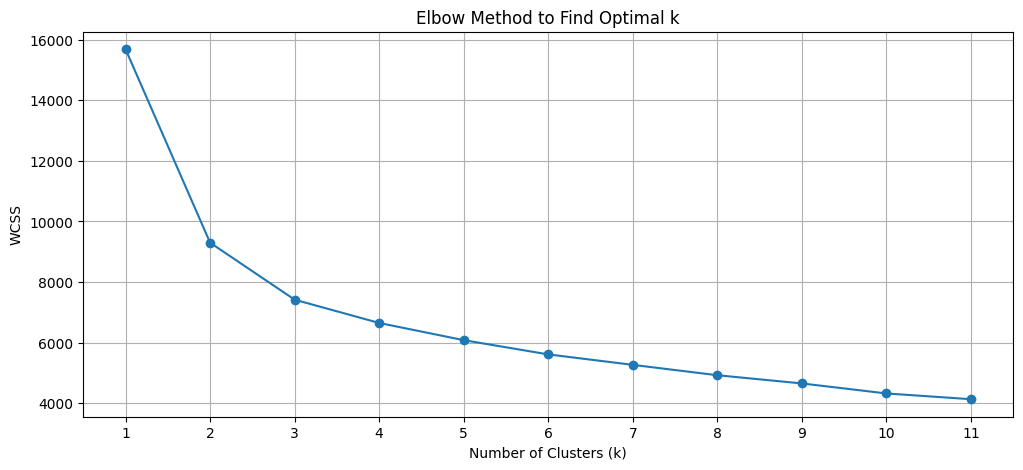

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(range(1, 12), wcss, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method to Find Optimal k")
plt.xticks(range(1, 12))
plt.grid(True)
plt.show()

In [12]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["Income", "Total_Spending", "Cluster"]].head(10))

    Income  Total_Spending  Cluster
0  58138.0            1617        4
1  46344.0              27        1
2  71613.0             776        4
3  26646.0              53        1
4  58293.0             422        2
5  62513.0             716        4
6  55635.0             590        4
7  33454.0             169        1
8  30351.0              46        1
9   5648.0              49        1


In [13]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", score)

Silhouette Score: 0.35856751222383243


In [14]:
from sklearn.cluster import DBSCAN

In [15]:
dbscan = DBSCAN(eps=0.75, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)
df["DBSCAN_Cluster"] = dbscan_labels
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))

In [16]:
print("DBSCAN clusters found (excluding noise):", n_clusters)
print("Customers labelled as noise:", n_noise)
print("Noise percentage:", round(100 * n_noise / len(dbscan_labels), 2), "%")

DBSCAN clusters found (excluding noise): 5
Customers labelled as noise: 732
Noise percentage: 32.68 %


In [17]:
display(
    pd.Series(dbscan_labels, name="DBSCAN_Cluster")
    .value_counts()
    .sort_index()
    .to_frame()
)

,count
DBSCAN_Cluster,
-1,732
0,1257
1,221
2,13
3,9
4,8


In [29]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))
print("Total variance shown in 2D:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


Explained variance ratio: [0.514 0.201]
Total variance shown in 2D: 71.48 %


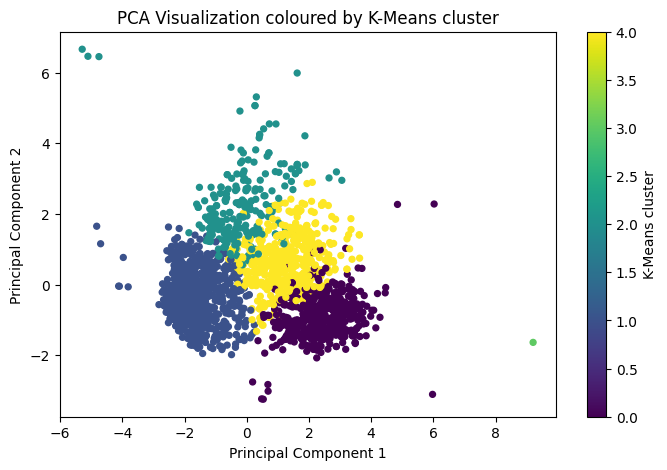

In [30]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['Cluster'], s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization coloured by K-Means cluster")
plt.colorbar(scatter, label="K-Means cluster")
plt.show()

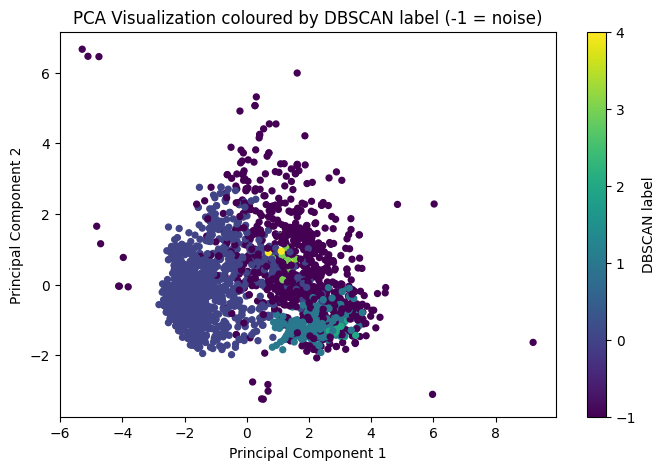

In [31]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization coloured by DBSCAN label (-1 = noise)")
plt.colorbar(scatter, label="DBSCAN label")
plt.show()

In [32]:
from sklearn.manifold import TSNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)
X_tsne = tsne.fit_transform(X_scaled)

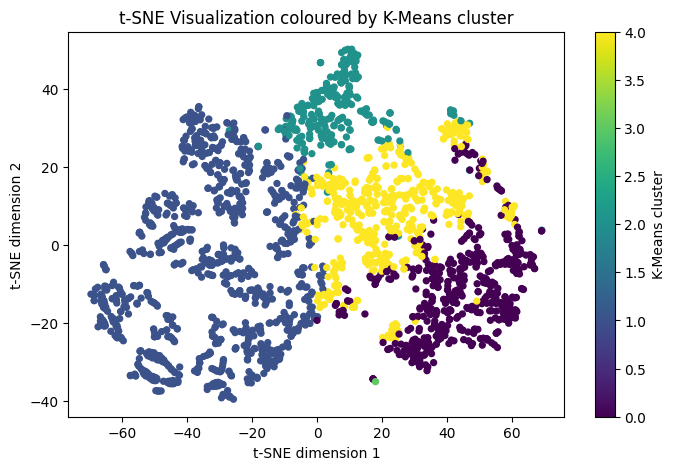

In [33]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=df['Cluster'], s=18)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Visualization coloured by K-Means cluster")
plt.colorbar(scatter, label="K-Means cluster")
plt.show()

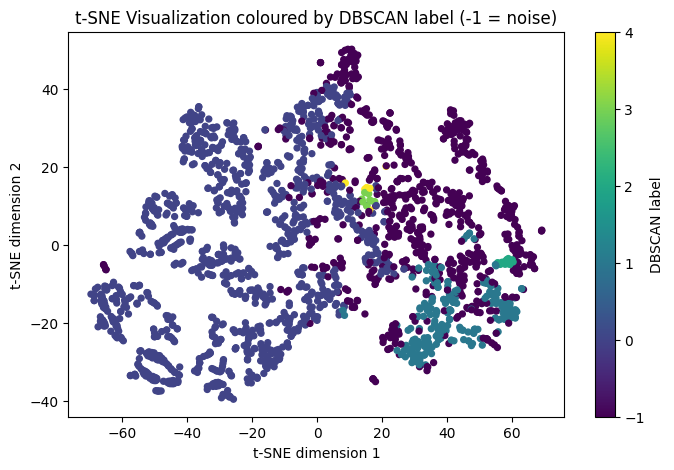

In [34]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=dbscan_labels, s=18)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Visualization coloured by DBSCAN label (-1 = noise)")
plt.colorbar(scatter, label="DBSCAN label")
plt.show()